# US Treasury yield curve modelling
**Sam Berman, University College Dublin**

This notebook runs the full analysis end to end by calling the functions in `src/` (the same code that `python -m src.pipeline` runs), and displays every table and figure. Data are downloaded from FRED on first run and cached in `data/raw/`.

Sections: 1. Data · 2. Nelson–Siegel / Svensson curve fitting · 3. PCA of daily yield changes · 4. Recession probits (out of sample) · 5. DV01-neutral 2s10s curve trades.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, display
from src import pipeline, data, curves
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
pipeline.setup()
FIG = ROOT / "figures"
def show(name, width=900):
    display(Image(filename=str(FIG / f"{name}.png"), width=width))

## 1. Data
FRED daily constant-maturity Treasury yields (DGS1MO … DGS30) and the monthly NBER recession indicator (USREC). The curve analysis starts on the first date all eleven maturities exist (2001-07-31, first 1-month print). FRED's DGS30 between 2002-02-19 and 2006-02-08 is Treasury's extrapolated estimate, not a market yield (note the jumps of +17bp and −16bp at the two ends), so it is set to missing.

Curve sample: 2001-07-31 to 2026-10-21 (6308 days)
Sources used: {'DGS1MO': 'FRED (cached)', 'DGS3MO': 'FRED (cached)', 'DGS6MO': 'FRED (cached)', 'DGS1': 'FRED (cached)', 'DGS2': 'FRED (cached)', 'DGS3': 'FRED (cached)', 'DGS5': 'FRED (cached)', 'DGS7': 'FRED (cached)', 'DGS10': 'FRED (cached)', 'DGS20': 'FRED (cached)', 'DGS30': 'FRED (cached)', 'USREC': 'FRED (cached)'}


,first obs,missing days in curve sample
DGS1MO,2001-07-31,0
DGS3MO,1981-09-01,0
DGS6MO,1981-09-01,0
DGS1,1962-01-02,0
DGS2,1976-06-01,0
DGS3,1962-01-02,0
DGS5,1962-01-02,0
DGS7,1969-07-01,0
DGS10,1962-01-02,0
DGS20,1962-01-02,0


DGS30 around the start of the extrapolated window (raw FRED values):


,DGS10,DGS20,DGS30
observation_date,,,
2002-02-12,4.97,5.69,5.45
2002-02-13,5.01,5.72,5.47
2002-02-14,4.95,5.64,5.42
2002-02-15,4.86,5.58,5.37
2002-02-19,4.88,5.61,5.54
2002-02-20,4.88,5.60,5.53
2002-02-21,4.88,5.58,5.53
2002-02-22,4.84,5.55,5.48


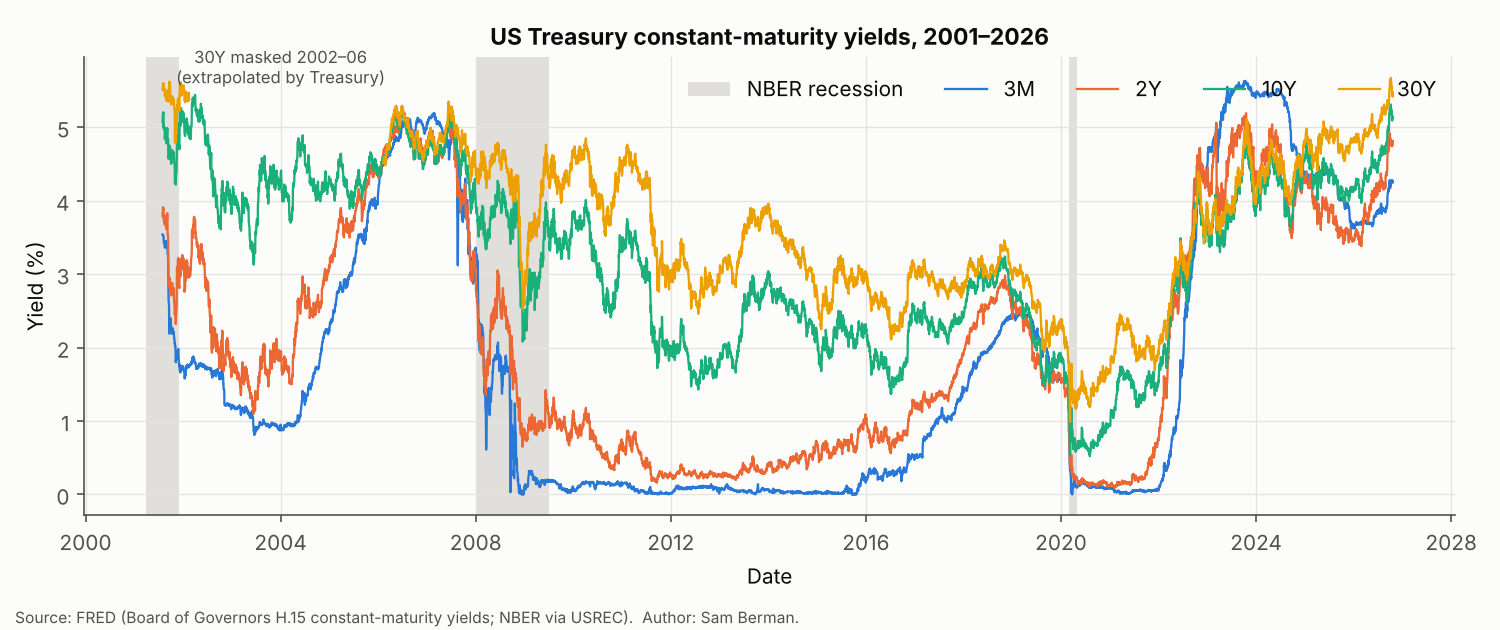

In [2]:
yields, yields_full, usrec = pipeline.section_data()
print("Curve sample:", yields.index[0].date(), "to", yields.index[-1].date(), f"({len(yields)} days)")
print("Sources used:", data.SOURCES_USED)
avail = pd.DataFrame({"first obs": [yields_full[c].first_valid_index().date() for c in yields_full],
                      "missing days in curve sample": yields.isna().sum()}, index=yields_full.columns)
display(avail)
print("DGS30 around the start of the extrapolated window (raw FRED values):")
display(data.load_yields(mask_30y_gap=False).loc["2002-02-12":"2002-02-22", ["DGS10", "DGS20", "DGS30"]])
show("fig01_yields_history")

## 2. Curve fitting: Nelson–Siegel and Nelson–Siegel–Svensson
Fitted every day by profile least squares (OLS for the betas on a grid of decay parameters). Three main specifications: NS with the Diebold–Li fixed decay (tau = 1.37y), NS with tau re-estimated daily, and NSS. A wide-grid NSS is included to show what happens when the decay parameters are left almost unconstrained. Out-of-sample check: drop one maturity, refit, predict it (leave-one-maturity-out).

In [3]:
fits, summary, loo_table, mapping = pipeline.section_curves(yields, usrec)
display(summary)
display(loo_table)

,params,mean RMSE (bp),median RMSE (bp),95th pct RMSE (bp),max RMSE (bp),LOO MAE (bp),median |daily chg b0| (bp),median |daily chg b2| (bp),% days |beta| > 20pp,% days tau1 at grid edge
model,,,,,,,,,,
NS (fixed tau),3,10.393,9.493,20.438,48.704,11.283,3.561,8.140,0.000,NaN
NS,4,5.569,4.697,11.119,29.490,6.537,3.782,9.122,0.000,9.004
NSS,6,3.162,2.833,6.812,14.707,5.776,5.274,16.287,0.032,7.055
NSS (wide tau grid),6,2.637,2.372,5.546,12.406,6.898,10.620,20.308,11.271,2.473


,NS (fixed tau),NS,NSS,NSS (wide tau grid)
3M,4.908,3.762,3.481,3.623
6M,11.271,6.723,4.285,4.145
1Y,14.816,6.243,4.558,4.376
2Y,9.533,4.457,3.074,3.360
3Y,5.076,4.700,3.232,3.188
5Y,13.146,4.996,2.792,3.196
7Y,12.217,4.990,3.922,4.059
10Y,11.481,7.601,7.731,7.673
20Y,19.096,15.358,18.905,28.467


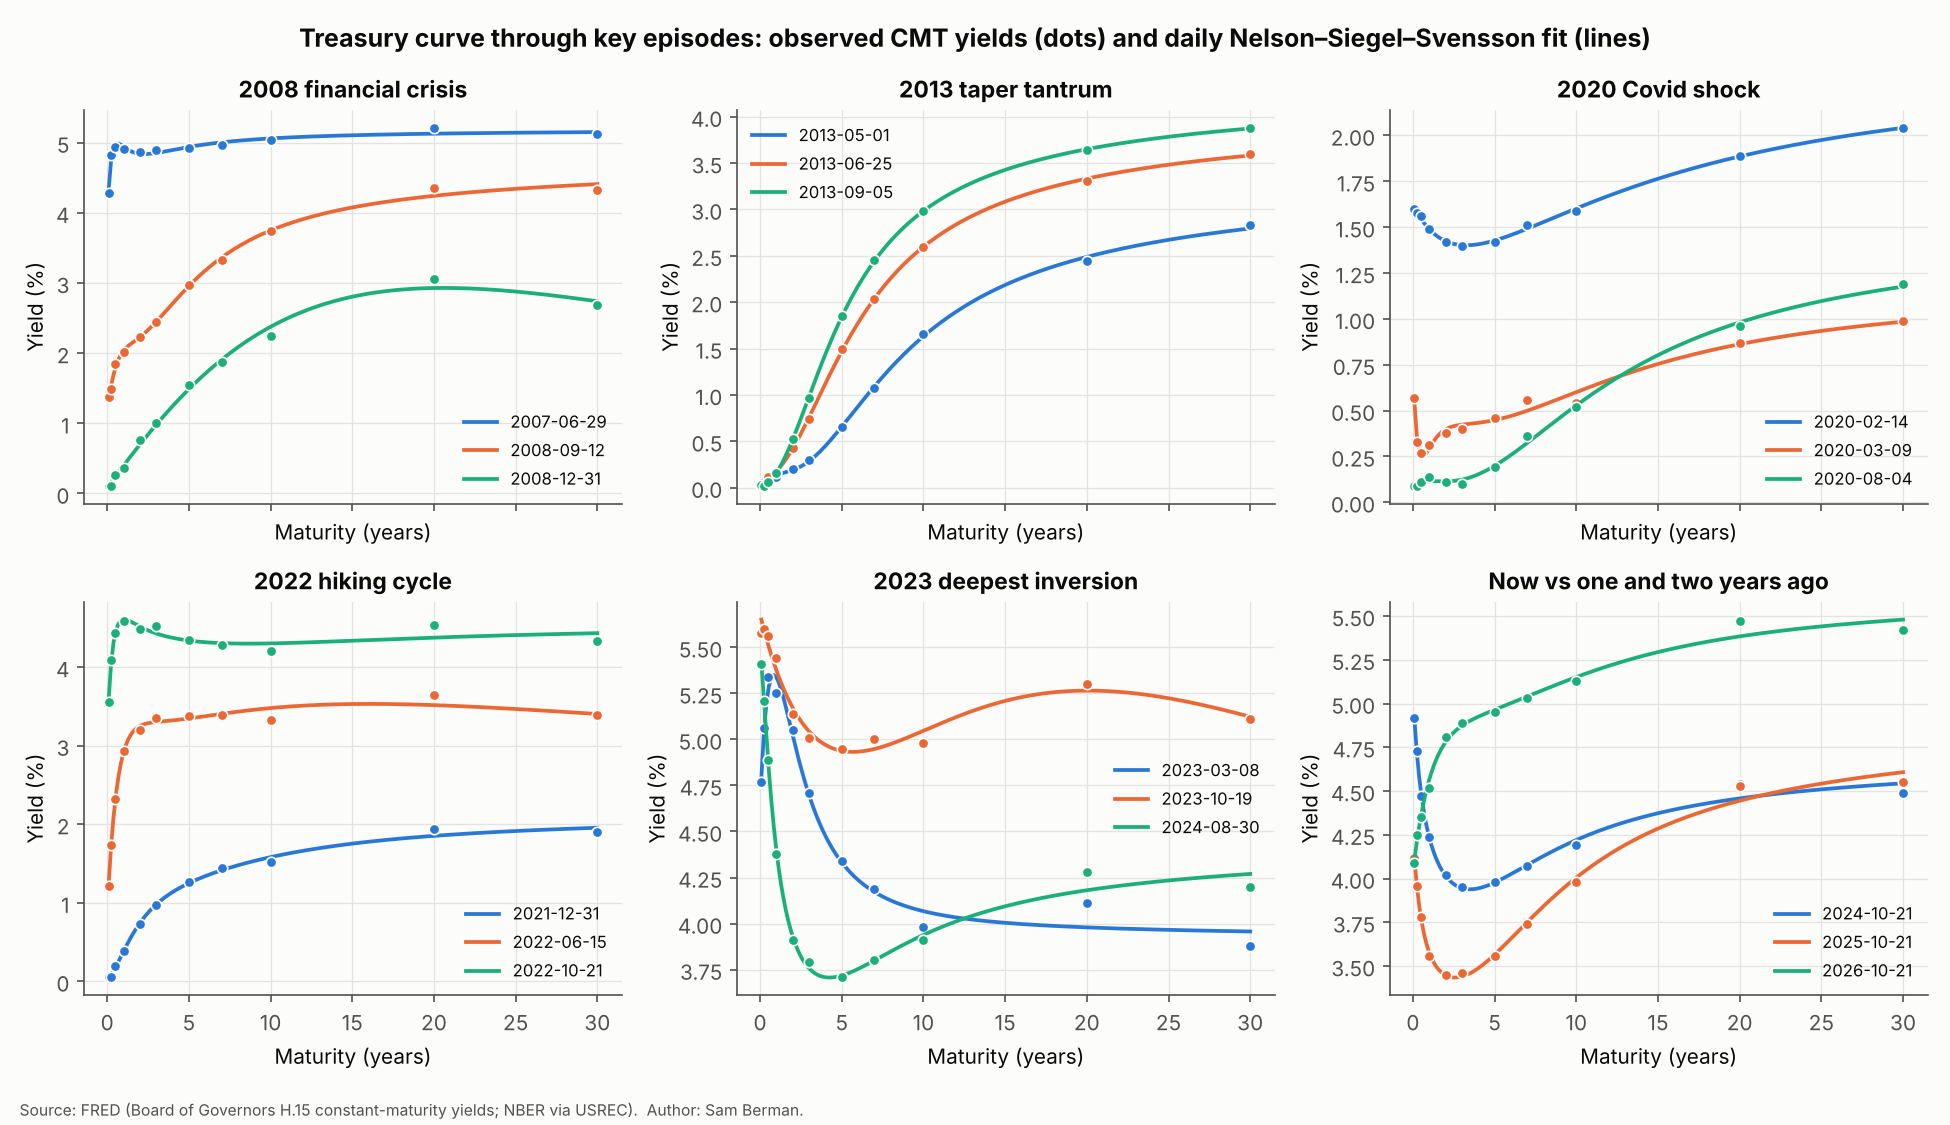

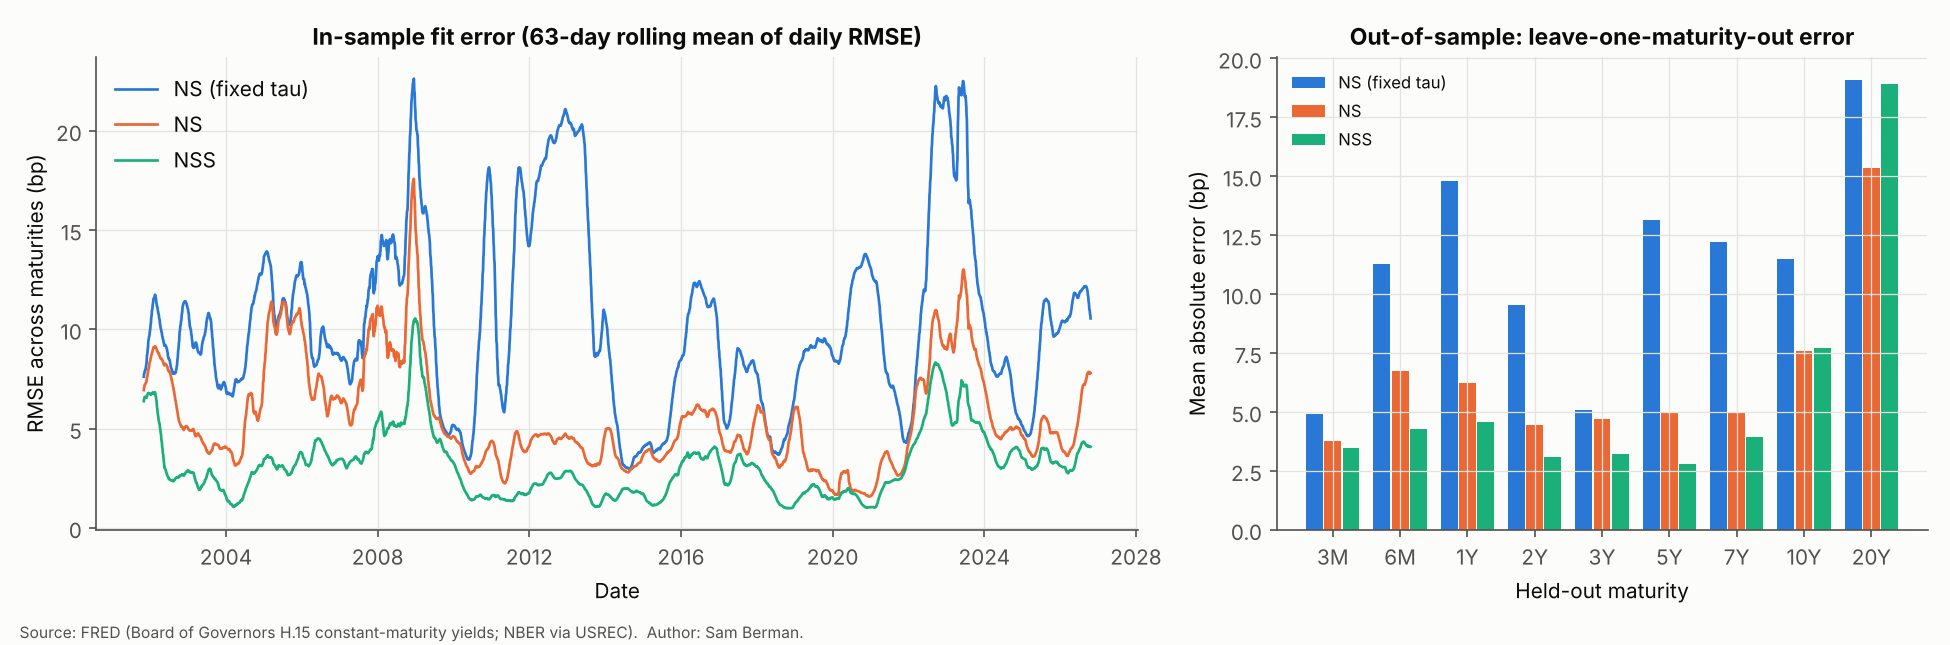

In [4]:
show("fig02_curve_episodes", 1000)
show("fig03_fit_errors", 1000)

### Mapping NS parameters to level, slope and curvature
b0 is the yield at infinite maturity (level), b0 + b1 is the instantaneous short rate, so −b1 is the long-minus-short slope, and b2 loads on the medium-term hump (curvature).

NS parameter  corr (levels)  corr (daily changes)
model          factor                                                           
NS (fixed tau) level                     b0          0.602                 0.698
               level (20Y)               b0          0.974                 0.970
               slope                    -b1          0.996                 0.929
               curvature                 b2          0.979                 0.851
               short rate (3M)        b0+b1          0.997                 0.789
NS             level                     b0          0.572                 0.240
               level (20Y)               b0          0.914                 0.367
               slope                    -b1          0.958                 0.385
               curvature                 b2          0.636                 0.206
               short rate (3M)        b0+b1          0.993                 0.478

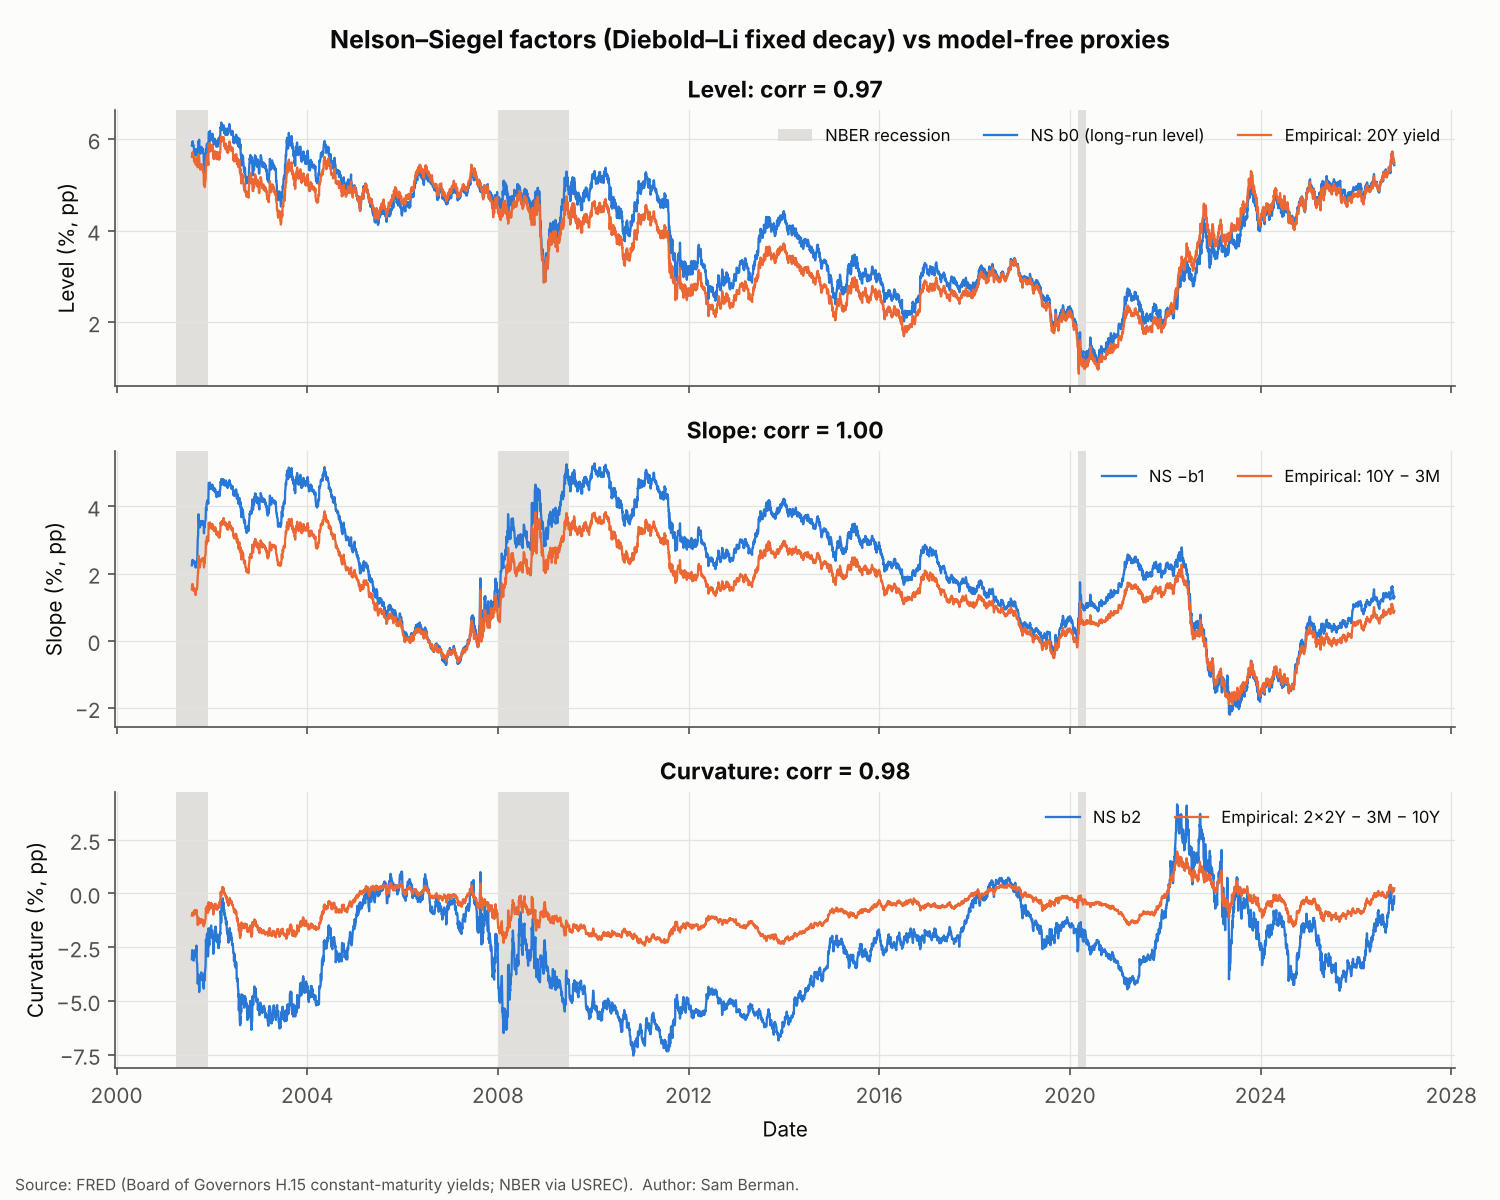

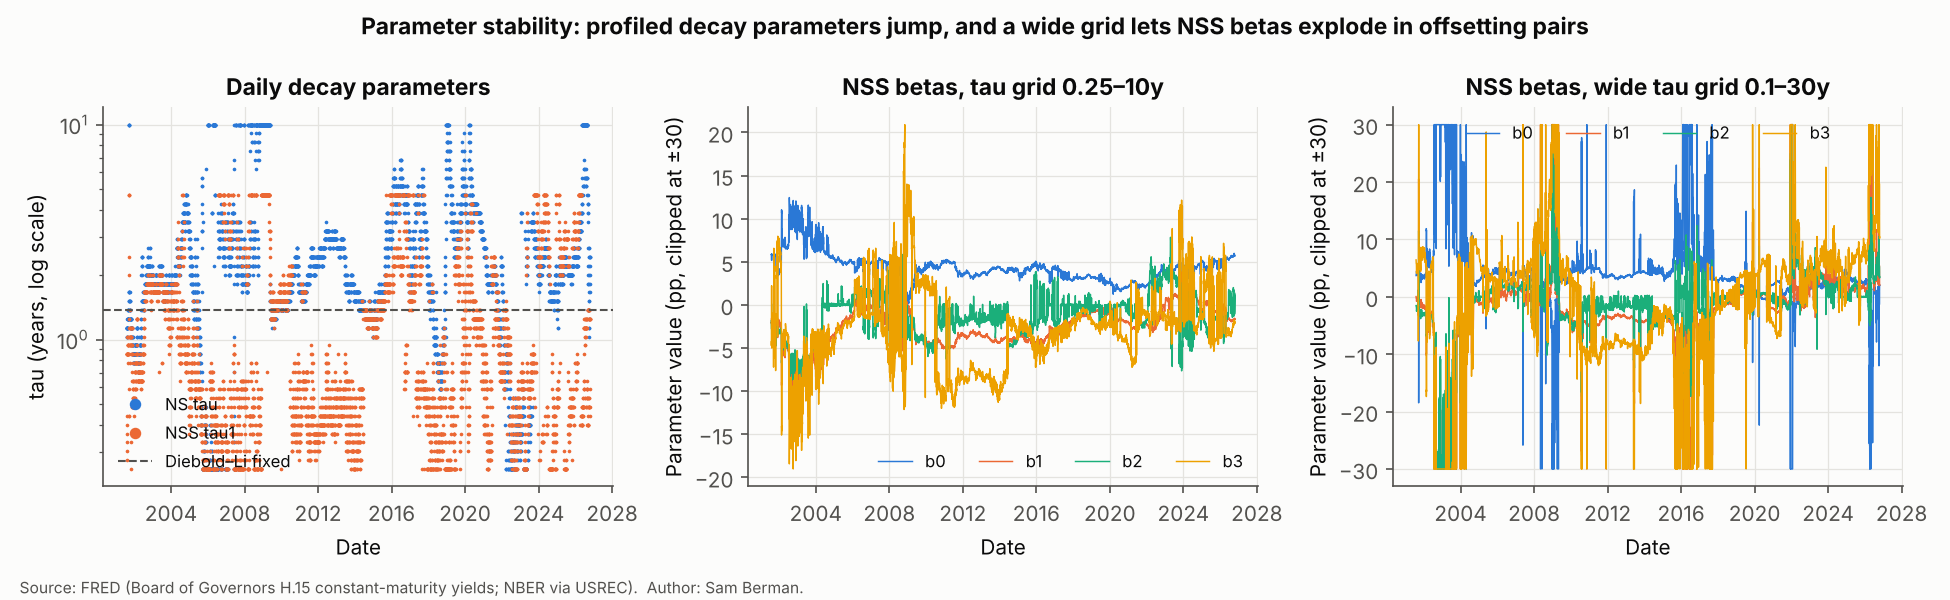

In [5]:
display(mapping)
show("fig04_ns_factors")
show("fig05_parameter_stability", 1000)

## 3. PCA of daily yield changes (3M–20Y)
The 1-month bill is excluded from the main specification because its daily changes are dominated by bill-supply and debt-ceiling noise; the 30Y is excluded because of its 2002–06 gap. Both are added back as robustness checks.

,variance share %,cumulative %,std dev (bp/day)
PC1,78.029,78.029,13.959
PC2,12.582,90.611,5.605
PC3,5.265,95.876,3.626
PC4,1.780,97.656,2.109
PC5,0.852,98.509,1.459


,PC1,PC2,PC3,PC4,PC5
3M,0.108,-0.594,-0.562,-0.520,-0.192
6M,0.146,-0.471,-0.175,0.457,0.506
1Y,0.222,-0.393,0.154,0.556,-0.232
2Y,0.354,-0.205,0.461,-0.107,-0.463
3Y,0.396,-0.098,0.356,-0.235,0.055
5Y,0.427,0.079,0.103,-0.215,0.374
7Y,0.425,0.192,-0.093,-0.092,0.304
10Y,0.392,0.259,-0.256,0.070,0.017
20Y,0.345,0.331,-0.453,0.293,-0.450


,PC1,PC2,PC3,PC1-3
"Main: 3M–20Y, 2001–2026",78.029,12.582,5.265,95.876
"Add 1M: 1M–20Y, 2001–2026",68.233,17.291,7.172,92.696
"All 11: 1M–30Y, 2006–2026",65.848,17.854,8.272,91.974


,start,end,days,PC1 var %,PC1 congruence,PC2 var %,PC2 congruence,PC3 var %,PC3 congruence,PC1-3 var %
period,,,,,,,,,,
2001-08 pre-ZLB,2001-08-01,2008-12-15,1843,76.413,0.987,16.343,0.930,3.644,0.913,96.400
2008-15 zero lower bound,2008-12-16,2015-12-15,1752,87.792,0.949,7.035,0.516,1.683,0.240,96.511
2015-22 normalisation/Covid,2015-12-16,2022-03-16,1563,79.959,0.991,9.635,0.953,5.080,0.930,94.674
2022-26 hiking and after,2022-03-17,2026-10-21,1149,83.184,0.994,9.177,0.935,4.153,0.935,96.514


,train 2001–13 loadings on 2014–26 data %,2014–26 own loadings (in-sample) %
PC1-1,80.816,81.159
PC1-2,89.522,91.335
PC1-3,95.486,95.745


,PC1,PC2,PC3
level (b0),0.787,0.406,-0.435
slope (-b1),0.586,0.758,-0.021
curvature (b2),0.502,-0.130,0.752


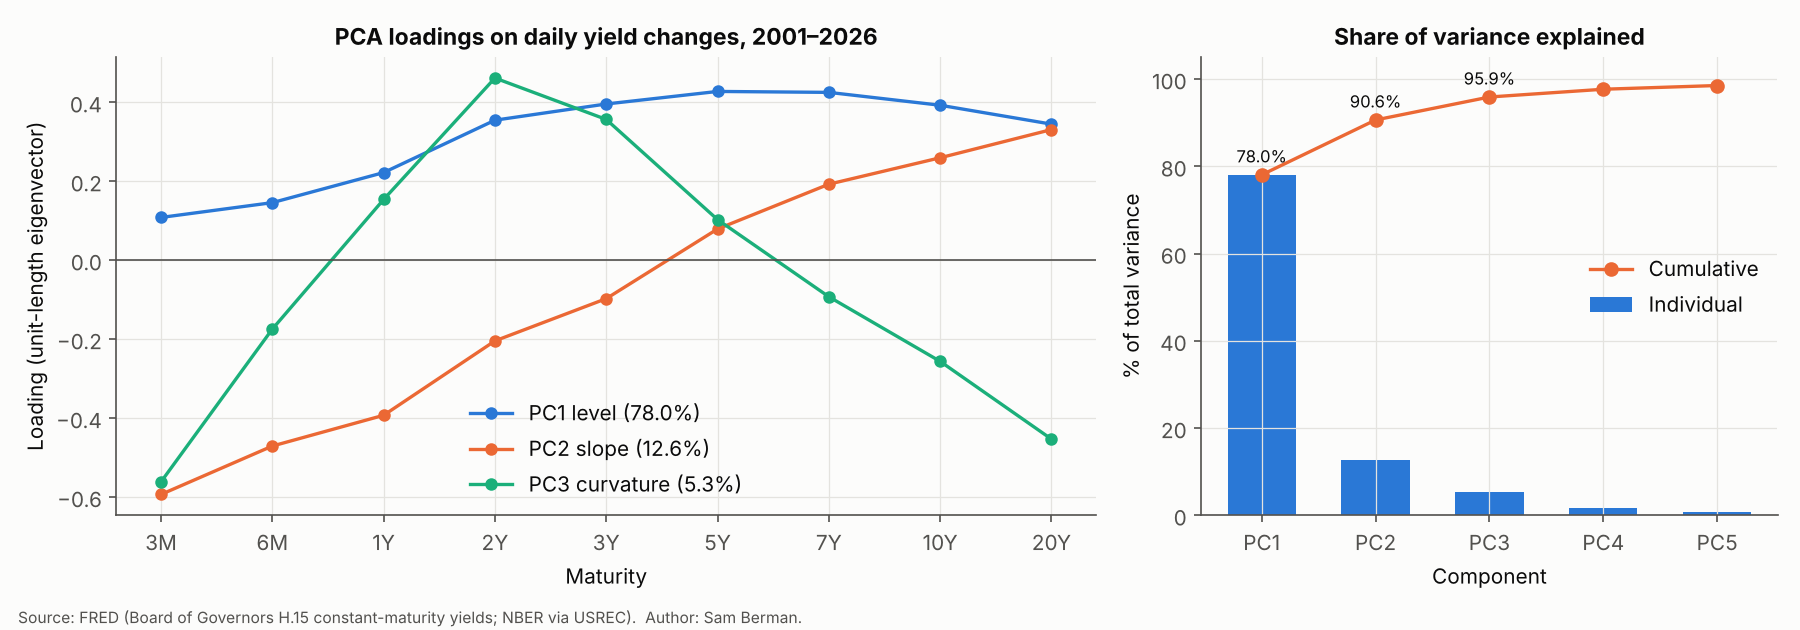

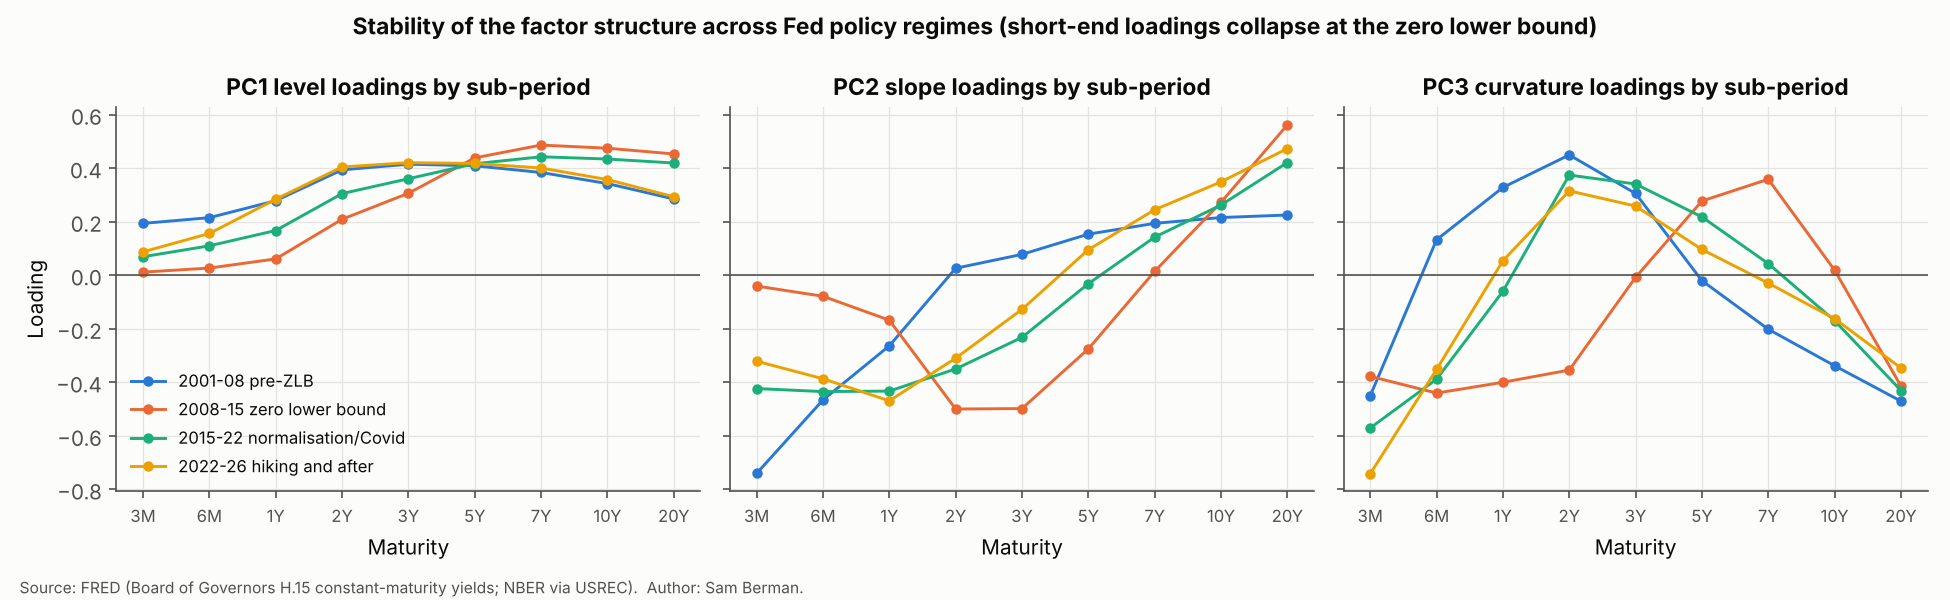

In [6]:
full, expl, robust, stab, oos_tab, link = pipeline.section_pca(yields, fits["NS (fixed tau)"].params)
display(expl); display(full.loadings.rename(index=data.LABELS))
display(robust); display(stab); display(oos_tab); display(link)
show("fig06_pca_loadings"); show("fig07_pca_stability", 1000)

## 4. Recession prediction (Estrella–Mishkin probits, 12 months ahead)
Full-sample probits with Newey–West (HAC) standard errors for inference, then expanding-window probits for out-of-sample probabilities. At each origin month t, the model only uses outcomes that NBER would have published by t (assumed 12-month publication lag).

,sample,months,a,b,z (HAC),p-value,McFadden R2,spread at P=50%
spread,,,,,,,,
10y-3m,1981-09–2025-09,529,-0.986,-0.433,-2.758,0.006,0.133,-2.279
10y-2y,1976-06–2025-09,592,-0.930,-0.756,-2.665,0.008,0.178,-1.229


first origin last evaluated origin  months  recession months    AUC  AUC 95% CI low  AUC 95% CI high  Brier  \
spread window                                                                                                                                          
10y-3m full OOS                               1988-08               2025-09     446                36  0.756           0.581            0.949  0.086   
       common window                          1988-08               2025-09     446                36  0.756           0.581            0.949  0.086   
       common window, origins to 2021-12      1988-08               2021-12     401                36  0.807           0.633            0.972  0.068   
10y-2y full OOS                               1983-05               2025-09     509                36  0.704           0.489            0.957  0.066   
       common window                          1988-08               2025-09     446                36  0.698           0.488            0.963  0.075   
       common window, origins to 2021-12      1988-08               2021-12     401                36  0.750           0.533            0.994  0.073   

                                          Brier (base rate)  Brier skill score  DM stat  DM p-value  
spread window                                                                                        
10y-3m full OOS                                       0.078             -0.105   -0.403       0.687  
       common window                                  0.078             -0.105   -0.403       0.687  
       common window, origins to 2021-12              0.086              0.204    1.230       0.219  
10y-2y full OOS                                       0.076              0.132    1.326       0.185  
       common window                                  0.078              0.040    0.396       0.692  
       common window, origins to 2021-12              0.085              0.144    1.982       0.047

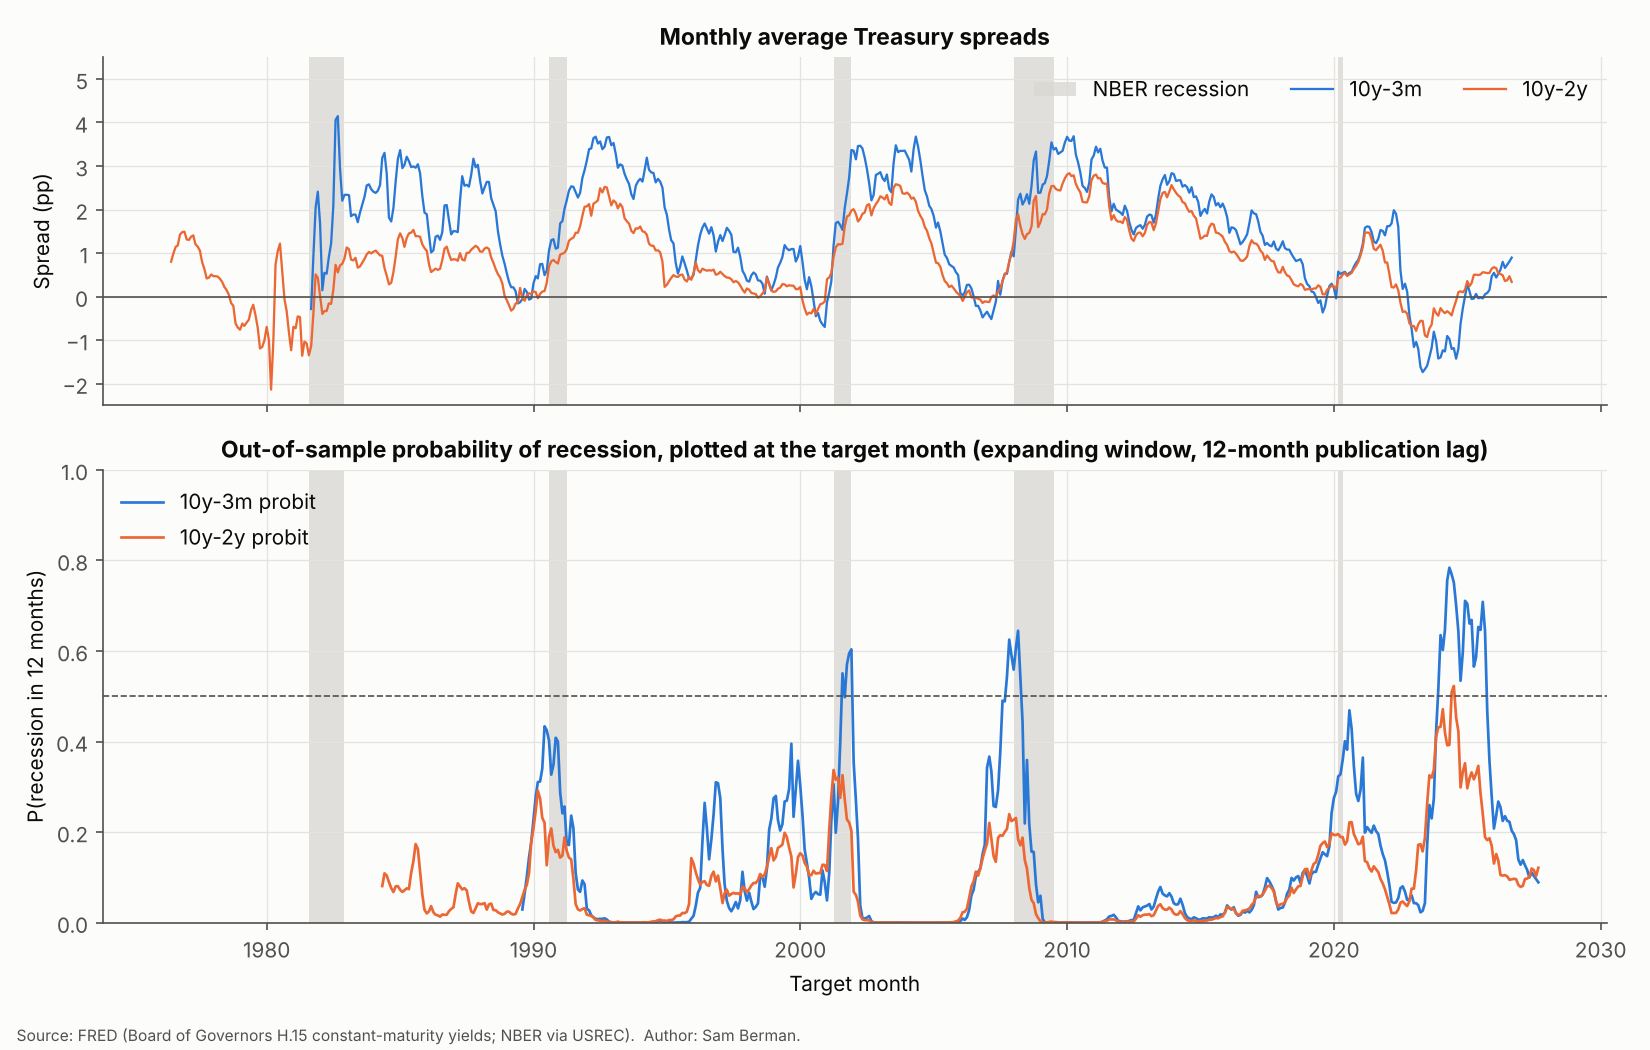

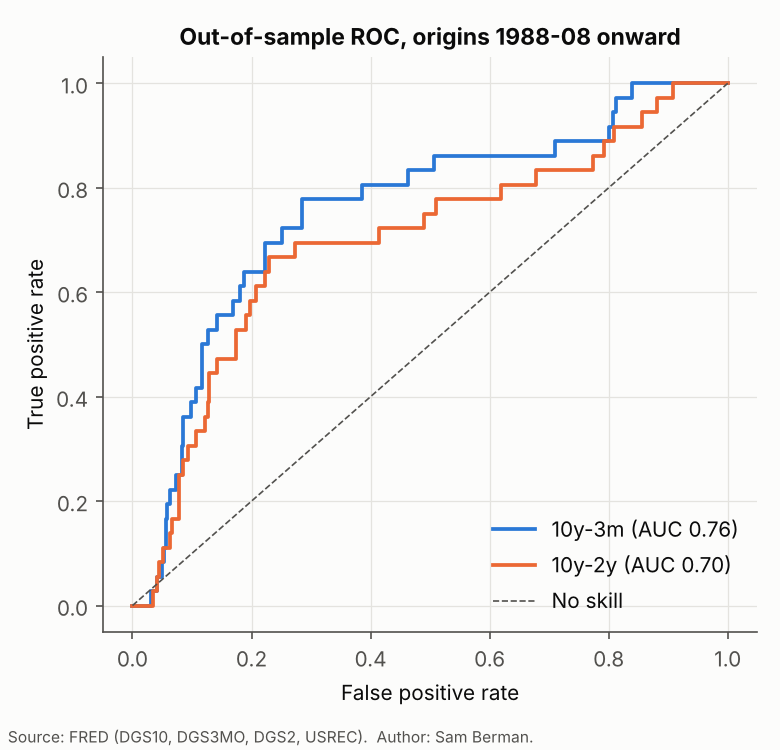

In [7]:
ms, ins, fcs, oos = pipeline.section_recession(yields_full, usrec)
display(ins)
display(oos)
show("fig08_recession_probabilities"); show("fig09_recession_roc", 450)

In [8]:
# The 2022-24 inversion: out-of-sample probabilities by origin month
p = pd.DataFrame({c: f.prob for c, f in fcs.items()}).loc["2022-01":]
display(p.resample("QS").mean().round(3))

,10y-3m,10y-2y
2022-01-01,0.042,0.121
2022-04-01,0.031,0.173
2022-07-01,0.220,0.303
2022-10-01,0.403,0.393
2023-01-01,0.628,0.442
2023-04-01,0.770,0.431
2023-07-01,0.699,0.466
2023-10-01,0.615,0.328
2024-01-01,0.678,0.316
2024-04-01,0.602,0.331


## 5. DV01-neutral 2s10s curve trades
Daily P&L per leg = carry over funding + roll-down + (−MD·Δy + ½·C·Δy²), each leg sized to $10k DV01. Parameters chosen on 1981–2001 only; everything from 2001-07-31 is out of sample. Costs 0.5bp of yield per leg per trade, with sensitivity.

ann. P&L ($k)  ann. vol ($k)  Sharpe  t-stat (NW)    p-value  max drawdown ($k)  hit rate  time in market  \
strategy                           period P&L                                                                                                                
Slope mean reversion (W=63, z=2.0) train  gross        -48.369        534.633  -0.090       -0.391  6.962e-01          -2624.991     0.514           0.552   
                                          net         -129.414        538.582  -0.240       -1.052  2.928e-01          -3304.991     0.511           0.552   
                                   test   gross        -98.025        507.797  -0.193       -1.010  3.124e-01          -5385.905     0.519           0.618   
                                          net         -161.144        508.015  -0.317       -1.685  9.195e-02          -6405.905     0.517           0.618   
Carry & roll-down (threshold 5bp)  train  gross        747.280        644.949   1.159        5.202  2.054e-07          -1268.570     0.565           0.894   
                                          net          703.718        645.153   1.091        4.902  9.812e-07          -1278.570     0.564           0.894   
                                   test   gross        102.477        490.149   0.209        1.139  2.546e-01          -3069.975     0.565           0.621   
                                          net          -67.307        491.756  -0.137       -0.750  4.533e-01          -3951.631     0.558           0.621   
Always steepener (benchmark)       train  gross        789.162        673.620   1.172        5.277  1.367e-07          -1519.811     0.555           1.000   
                                          net          788.655        673.657   1.171        5.274  1.388e-07          -1519.811     0.555           1.000   
                                   test   gross          2.058        620.192   0.003        0.018  9.860e-01          -3502.972     0.490           1.000   
                                          net            2.058        620.192   0.003        0.018  9.860e-01          -3502.972     0.490           1.000   

                                                 trades / yr  
strategy                           period P&L                 
Slope mean reversion (W=63, z=2.0) train  gross        6.737  
                                          net          6.737  
                                   test   gross        6.312  
                                          net          6.312  
Carry & roll-down (threshold 5bp)  train  gross        4.356  
                                          net          4.356  
                                   test   gross       16.978  
                                          net         16.978  
Always steepener (benchmark)       train  gross        0.051  
                                          net          0.051  
                                   test   gross        0.000  
                                          net          0.000

strategy,Always steepener (benchmark),Carry & roll-down (threshold 5bp),"Slope mean reversion (W=63, z=2.0)"
cost (bp/leg),,,
0.00,0.003,0.209,-0.193
0.25,0.003,0.036,-0.255
0.50,0.003,-0.137,-0.317
1.00,0.003,-0.477,-0.440
2.00,0.003,-1.119,-0.679


,carry,rolldown,duration,convexity,total
always-steepener ann. $k (test),-3.201,74.457,-37.153,-32.045,2.058


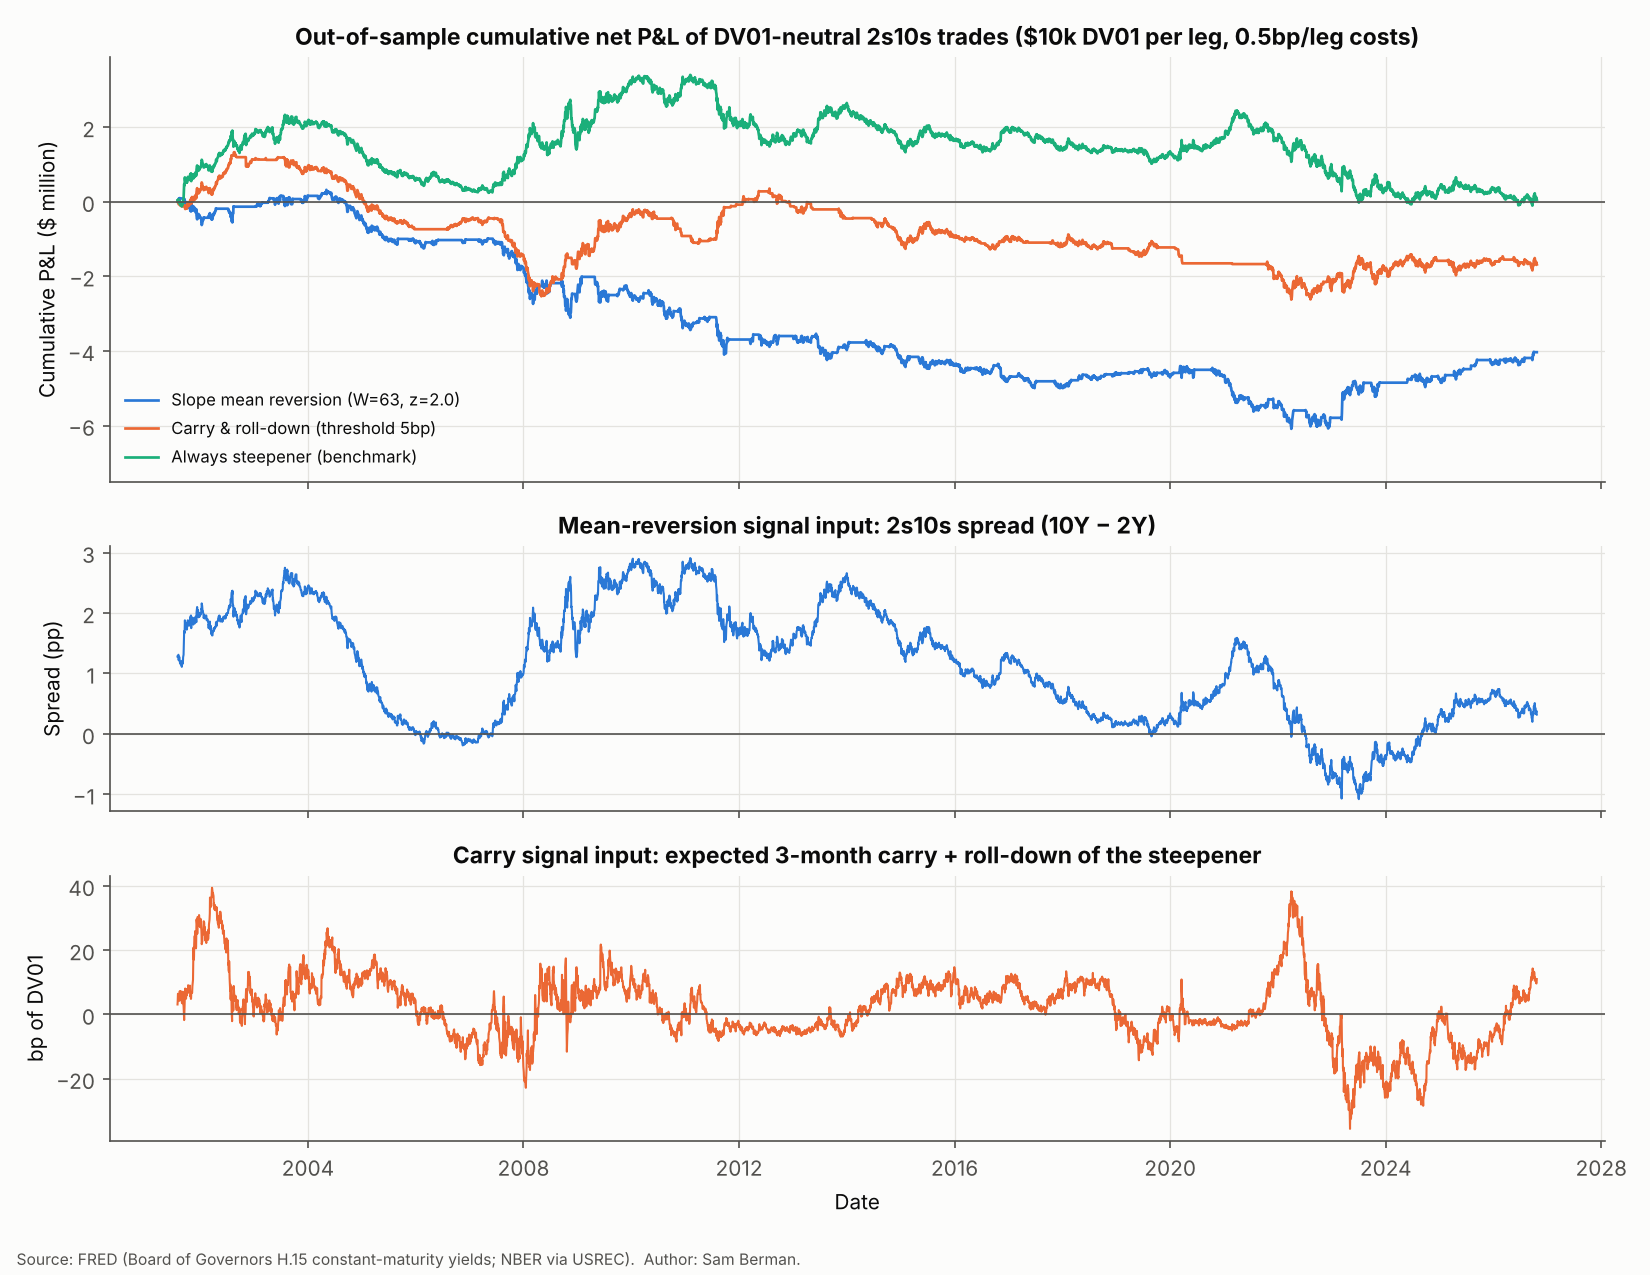

In [9]:
pnl, positions, perf, costs, attrib = pipeline.section_trades(yields_full)
display(perf)
display(costs)
display(attrib)
show("fig10_curve_trades")

In [10]:
# Training-period parameter grids (selection by training Sharpe only)
display(pd.read_csv(ROOT / "results/trades_train_grid_zscore.csv", index_col=0))
display(pd.read_csv(ROOT / "results/trades_train_grid_carry.csv", index_col=0))

,window,entry z,train Sharpe
0,63,0.5,-0.460
1,63,1.0,-0.256
2,63,1.5,-0.305
3,63,2.0,-0.240
4,126,0.5,-0.269
5,126,1.0,-0.422
6,126,1.5,-0.482
7,126,2.0,-0.517
8,252,0.5,-0.530
9,252,1.0,-0.508


,threshold bp,train Sharpe
0,0.0,1.024
1,2.0,1.059
2,5.0,1.091
3,10.0,0.948


## Key numbers

In [11]:
(ROOT / "results").mkdir(exist_ok=True)
(ROOT / "results/key_numbers.json").write_text(json.dumps(pipeline.K, indent=2, default=str))
print(json.dumps(pipeline.K, indent=2, default=str))

{
  "sample_start": "2001-07-31",
  "sample_end": "2026-10-21",
  "n_days": 6308,
  "dgs30_masked_days": 994,
  "sources": {
    "DGS1MO": "FRED (cached)",
    "DGS3MO": "FRED (cached)",
    "DGS6MO": "FRED (cached)",
    "DGS1": "FRED (cached)",
    "DGS2": "FRED (cached)",
    "DGS3": "FRED (cached)",
    "DGS5": "FRED (cached)",
    "DGS7": "FRED (cached)",
    "DGS10": "FRED (cached)",
    "DGS20": "FRED (cached)",
    "DGS30": "FRED (cached)",
    "USREC": "FRED (cached)"
  },
  "rmse_mean_bp[NS (fixed tau)]": 10.39,
  "loo_mae_bp[NS (fixed tau)]": 11.28,
  "rmse_mean_bp[NS]": 5.57,
  "loo_mae_bp[NS]": 6.54,
  "rmse_mean_bp[NSS]": 3.16,
  "loo_mae_bp[NSS]": 5.78,
  "rmse_mean_bp[NSS wide]": 2.64,
  "loo_mae_bp[NSS wide]": 6.9,
  "blowup_pct[NSS wide]": 11.27,
  "rmse_by_year_NSS": {
    "2001": 6.61,
    "2002": 3.27,
    "2003": 2.17,
    "2004": 2.3,
    "2005": 3.25,
    "2006": 3.65,
    "2007": 3.96,
    "2008": 6.56,
    "2009": 4.72,
    "2010": 1.67,
    "2011": 1.6,
    "